# 09 · Power BI Executive Dashboard - data model, DAX and validation
**Customer Revenue Intelligence**, Step 11

> ⚠️ **SYNTHETIC DATA.** Everything here comes from the validated Step 10 database
> `data/customer_revenue_intelligence.db` and the saved Step 8 / Step 9 model metadata.

> ⚠️ **Power BI Desktop is Windows-only and cannot run in this environment.** This notebook builds
> and validates everything the report *reads* - the star-schema extracts, the DAX library, the
> theme, the recommendation content and the target values to check the cards against. The `.pbix`
> itself is assembled by hand following `powerbi/POWERBI_BUILD_GUIDE.md`. The page images below are
> **design mockups drawn from the real data**, watermarked as such - not screenshots of Power BI.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import Image, display
import config
from src import powerbi_prep as pb

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
MOCK = pb.MOCKUP_DIR

# Build the star-schema views, export every table, write the DAX / theme / docs,
# validate against SQL and render the mockups. Fully reproducible.
R = pb.run_powerbi_prep(make_mockups=True, verbose=True)

Tables exported      : 13 -> powerbi/data/
Relationships        : 9
DAX measures         : 84 in 10 display folders
Measure validation   : 48/48 Python-vs-SQL matches over 8 contexts
Cross-step checks    : 32/32 pass
Design mockups       : 10 (labelled, NOT Power BI screenshots)
Documents            : powerbi_dashboard_documentation.md, powerbi_user_guide.md, POWERBI_BUILD_GUIDE.md, README.md


## 1. The star schema

In [2]:
R["catalog"]

,Table,Role,Source,Rows,Columns,Grain
0,DimDate,Dimension,SQL view pbi_dim_date,1277,23,"One row per calendar day, 2023-01-01 to 2026-06-30"
1,DimGeography,Dimension,SQL view pbi_dim_geography,35,5,One row per customer city
2,DimProduct,Dimension,SQL view pbi_dim_product,61,4,One row per product
3,DimRFMSegment,Dimension,SQL view pbi_dim_rfm_segment,12,6,One row per Step 5 RFM segment (+ 'No delivered order')
4,DimCluster,Dimension,SQL view pbi_dim_cluster,5,4,One row per Step 6 K-Means cluster (+ 'No delivered order')
5,DimCustomer,Dimension,SQL view pbi_dim_customer,2000,36,One row per registered customer (no names; Customer_ID only)
6,FactSales,Fact,SQL view pbi_fact_sales,18670,19,"One row per order line, all statuses, with Is_Delivered"
7,FactForecast,Fact,SQL view pbi_fact_forecast,54,13,One row per month x forecast record type (Step 9)
8,FactRevenuePrediction,Fact,outputs/tables/revenue_predictions.csv (Step 8),2913,17,"One row per customer x target quarter, test split (Step 8)"
9,PredictionQuarterly,Fact (aggregated),outputs/tables/revenue_quarterly_totals.csv (Step 8),8,9,One row per target quarter: actual vs predicted totals (Step 8)


- **One fact for sales, keeping every status.** `FactSales` holds all 18,670 order lines with an
  `Is_Delivered` flag, so the same table answers "what did we earn" and "what did we lose to
  returns", and the two can never disagree.
- **Customer state lives on the customer dimension.** RFM, cluster and CLV fields are one-per-customer
  snapshots at the 2026-01-01 reference date, so they belong in `DimCustomer`.
- **No customer names.** Analytical outputs identify a customer by `Customer_ID` only.

In [3]:
dim = pd.read_csv(pb.PBI_DATA / "DimCustomer.csv")
print("name-like columns in DimCustomer:", [c for c in dim.columns if "name" in c.lower()])
dim.head(3).T.head(20)

name-like columns in DimCustomer: []


,0,1,2
Customer_ID,CUST-0146,CUST-1296,CUST-1405
Customer_Age,30,24,51
Age_Band,25-34,18-24,50+
Gender,Female,Male,Female
Home_Region,North,West,East
Has_Delivered_Order,1,1,1
Reference_Date,2026-01-01,2026-01-01,2026-01-01
First_Purchase_Date,2023-01-01,2023-01-01,2023-01-01
Last_Purchase_Date,2025-12-14,2023-01-01,2025-03-24
Acquisition_Status,Existing before 2023,Existing before 2023,Existing before 2023


## 2. The date table

In [4]:
d = pd.read_csv(pb.PBI_DATA / "DimDate.csv")
print(f"{len(d):,} days, {d.Date.min()} to {d.Date.max()}")
d.iloc[[0, 200, 1100]].T

1,277 days, 2023-01-01 to 2026-06-30


,0,200,1100
Date,2023-01-01,2023-07-20,2026-01-05
Year,2023,2023,2026
Quarter,Q1,Q3,Q1
Quarter_Number,1,3,1
Year_Quarter,2023-Q1,2023-Q3,2026-Q1
Year_Quarter_Sort,20231,20233,20261
Month_Number,1,7,1
Month_Name,January,July,January
Month_Short,Jan,Jul,Jan
Year_Month,2023-01,2023-07,2026-01


- **Covers the forecast horizon** (to 2026-06-30), so the Step 9 forecast rows have real dates to
  join to.
- `Month_Name` is sorted by `Month_Number` and the table is marked as the official date table -
  both are manual steps in Power BI Desktop, listed in the build guide.

## 3. Relationships

In [5]:
R["relationships"]

,From_Table,From_Column,To_Table,To_Column,Cardinality,Cross_Filter_Direction,Active,Notes
0,DimDate,Date,FactSales,Order_Date,One-to-many,Single,Yes,Date table marked in Power BI; drives every time intelligence measure
1,DimCustomer,Customer_ID,FactSales,Customer_ID,One-to-many,Single,Yes,
2,DimProduct,Product_ID,FactSales,Product_ID,One-to-many,Single,Yes,
3,DimGeography,Location_ID,FactSales,Location_ID,One-to-many,Single,Yes,Customer home location; one location per customer in this dataset
4,DimRFMSegment,RFM_Segment,DimCustomer,RFM_Segment,One-to-many,Single,Yes,"Snowflake on the customer dimension: segment attributes filter customers, which filter..."
5,DimCluster,Cluster_ID,DimCustomer,Cluster_ID,One-to-many,Single,Yes,Snowflake on the customer dimension
6,DimDate,Date,FactForecast,Month_Date,One-to-many,Single,Yes,Forecast rows join on the first day of the month
7,DimDate,Date,FactRevenuePrediction,Target_Quarter_Start,One-to-many,Single,No,"INACTIVE by design: the prediction grain is a quarter, so a date filter would silently..."
8,DimCustomer,Customer_ID,FactRevenuePrediction,Customer_ID,One-to-many,Single,Yes,Lets the prediction page respond to the customer and segment slicers


- The only **inactive** relationship is `DimDate → FactRevenuePrediction`: the prediction grain is a
  quarter, so an active date relationship would silently drop rows whenever a date slicer moved.

## 4. DAX measures

In [6]:
m = R["measures"]
print(f"{len(m)} measures in {m.Display_Folder.nunique()} display folders")
m.groupby("Display_Folder").size().rename("Measures").to_frame()

84 measures in 10 display folders


,Measures
Display_Folder,
01 Revenue,14
02 Profitability,7
03 Orders,6
04 Customers,9
05 Customer value,13
06 Segmentation (RFM & clusters),7
07 Products & regions,4
08 Prediction (Step 8 ML),8
09 Forecast (Step 9 time series),11


In [7]:
print((pb.PBI_DAX / "measures.dax").read_text()[:1800])

// =============================================================================
// Customer Revenue Intelligence - DAX measure library (STEP 11)
// SYNTHETIC DATA. Generated by src/powerbi_dax.py; do not edit by hand.
//
// How to use: in Power BI Desktop create a blank table called _Measures
// (Home > Enter data, one dummy column, load, then delete the column), and add
// each measure below to it. Set the Display folder and Format string shown in
// the comment above each measure.
//
// Conventions
//   * Revenue rule: only Delivered lines count. Every currency measure filters
//     FactSales[Is_Delivered] = 1, exactly as vw_delivered_sales does in SQL.
//   * Customer-state measures (recency, frequency, CLV, segment) are a SNAPSHOT
//     at the reference date 2026-01-01 taken in Steps 5-7. They sit on
//     DimCustomer and deliberately do NOT change with the Date slicer.
//   * "Inactive", never "churned" - no churn event is defined in this project.
//   * Historical / Predicted

## 5. Validation: the same measures in pandas and in SQL

In [8]:
v = R["validation"]
v[v.SQL_Value.notna()][["Filter_Context", "Measure", "Python_Value", "SQL_Value",
                        "Difference", "Reconciled"]].head(18)

,Filter_Context,Measure,Python_Value,SQL_Value,Difference,Reconciled
0,All data,Total Revenue,"60,056,569.15","60,056,569.15",0.00,Match
1,All data,Total Profit,"14,022,551.58","14,022,551.58",0.00,Match
3,All data,Profit Margin %,23.35,23.35,0.00,Match
4,All data,Total Orders,"12,212.00","12,212.00",0.00,Match
5,All data,Total Customers,"1,984.00","1,984.00",0.00,Match
7,All data,Average Order Value,"4,917.83","4,917.83",0.00,Match
15,Year = 2024,Total Revenue,"19,769,754.90","19,769,754.90",0.00,Match
16,Year = 2024,Total Profit,"4,557,848.19","4,557,848.19",0.00,Match
18,Year = 2024,Profit Margin %,23.05,23.05,0.00,Match
19,Year = 2024,Total Orders,"4,014.00","4,014.00",0.00,Match


In [9]:
v.Reconciled.value_counts().rename("Comparisons").to_frame()

,Comparisons
Reconciled,
Not recomputed in SQL,72
Match,48


- **48 of 48** Python-vs-SQL comparisons match, across 8 filter contexts (all data, 2024, 2025,
  Region = South, Category = Electronics, Champions, the High-Value Active cluster, and 2025-10).
- The file also carries an empty `Power_BI_Value` column: after the report is built, type what
  Power BI shows into it. `powerbi/dax/validation_query.dax` produces the same numbers from the
  finished report in one go.

## 6. Validation: the extracts still agree with Steps 4-9

In [10]:
R["consistency"]

,Area,Check,Star_Schema_Value,Reference_Value,Reference_Source,Status
0,Revenue,Total Revenue,"60,056,569.15","60,056,569.15",Step 4 outputs/tables/eda_kpis.csv,PASS
1,Revenue,Total Profit,"14,022,551.58","14,022,551.58",Step 4 eda_kpis.csv,PASS
2,Revenue,Total Cost,"46,034,017.57","46,034,017.57",Step 4 eda_kpis.csv,PASS
3,Orders,Total Orders,"12,212.00","12,212.00",Step 4 eda_kpis.csv,PASS
4,Customers,Purchasing customers,"1,984.00","1,984.00",Step 4 eda_kpis.csv,PASS
5,Orders,Average order value,"4,917.83","4,917.83",Step 4 eda_kpis.csv,PASS
6,Quantity,Units sold,"22,772.00","22,772.00",Step 4 eda_kpis.csv,PASS
7,Segmentation,Champions revenue,"32,330,090.40","32,330,090.40",Step 5 rfm_segment_summary.csv,PASS
8,Segmentation,Champions customers,334.00,334.00,Step 5 rfm_segment_summary.csv,PASS
9,Segmentation,"High-Value, Active cluster revenue","33,433,867.35","33,433,867.35",Step 6 ml_cluster_summary.csv,PASS


- **32 of 32 pass**: revenue, profit, cost, orders, customers and units against Step 4; Champions
  and cluster revenue against Steps 5-6; CLV totals against Step 7; monthly actuals and the forecast
  total against Step 9; prediction totals and MAE against Step 8; plus key uniqueness, orphan keys
  and the no-customer-name rule.

## 7. Model metrics are read, never retyped

In [11]:
mm = pd.read_csv(pb.PBI_DATA / "ModelMetrics.csv")
mm[mm.Split.str.startswith(("Test", "Rolling"))][["Model_Area", "Model", "Split", "Metric", "Value"]]

,Model_Area,Model,Split,Metric,Value
3,Revenue prediction (ML),Linear regression,Test (2025 Q3-Q4),MAE,"5,657.57"
4,Revenue prediction (ML),Linear regression,Test (2025 Q3-Q4),RMSE,"11,232.42"
5,Revenue prediction (ML),Linear regression,Test (2025 Q3-Q4),R2,0.06
6,Revenue prediction (ML),Linear regression,Test (2025 Q3-Q4),WAPE_%,127.83
7,Revenue prediction (ML),Linear regression,Test (2025 Q3-Q4),Spearman,0.18
8,Revenue prediction (ML),Linear regression,Test (2025 Q3-Q4),Total_Bias_%,1.12
9,Revenue prediction (ML),Baseline: 12-month quarterly mean,Test (2025 Q3-Q4),MAE,"5,436.15"
10,Revenue prediction (ML),Baseline: 12-month quarterly mean,Test (2025 Q3-Q4),RMSE,"11,466.32"
11,Revenue prediction (ML),Baseline: 12-month quarterly mean,Test (2025 Q3-Q4),R2,0.02
17,Revenue forecast (time series),Theta: Theta (seasonality auto-tested),Test (2025-07..12),MAE,"213,178.66"


- `ModelMetrics` is generated from `models/revenue_model_metadata.json` and
  `models/forecasting_metadata.json`, so a metric on the dashboard cannot drift from the metric in
  the model file.
- **MAPE is reported for the forecast and not for the prediction**: many customer-quarters have an
  actual of 0, which makes a percentage error undefined.

## 8. Recommendations, each traced to a saved analysis

In [12]:
r = pd.read_csv(pb.PBI_DATA / "Recommendations.csv")
r[["Area", "Recommendation", "Supporting_Metric", "Metric_Value", "Analytical_Source"]]

,Area,Recommendation,Supporting_Metric,Metric_Value,Analytical_Source
0,Customer,Protect the top revenue decile before chasing new customers,Top-20% revenue share,64.33%,SQL cust_concentration_summary (Step 10); Step 5 concentration analysis
1,Customer,Contact the 52 high-value customers who have not bought for 180+ days,Potentially at-risk high-value customers,52,Step 7 customer_value flags; SQL BQ06
2,Customer,Convert single-purchase buyers: they are 10.6% of customers but 1.4% of revenue,Revenue per repeat customer vs single-purchase,"₹33,378 vs ₹4,019","SQL BQ12, BQ17 (Step 10)"
3,Customer,"Treat Champions as a retention job, not an acquisition one",Champions revenue share,53.83%,Step 5 rfm_segment_summary; Step 6 ml_cluster_summary
4,Product,Stop judging Electronics on revenue alone,Electronics revenue share vs profit share,50.10% vs 23.29%,"SQL prod_category_performance, BQ04 (Step 10)"
5,Product,Review the 10 products the margin and returns rules flag,Products flagged,10,"SQL prod_investigate, BQ03 (Step 10)"
6,Product,"Treat discounting as a margin decision, not a volume lever",Categories where the 0% band has the best margin,6 of 6,"SQL prod_discount_bands, BQ08 (Step 10)"
7,Product,Attack Fashion returns: 14.44% of booked value is lost,Fashion booked value lost,14.44%,SQL BQ14 (Step 10)
8,Regional,"Grow Central and East on their margin, not on their size",Central margin vs South margin,25.26% vs 22.80%,"SQL reg_performance, BQ05 (Step 10)"
9,Regional,Do not build a region-specific pricing story - the differences are category mix,Region-category pairs more than 2pp below national margin,0 of 30,"SQL BQ16, reg_category_matrix (Step 10)"


## 9. Page design mockups

**These are not Power BI screenshots.** They are rendered with matplotlib from the exported
extracts, so every number on them is a real project output, and each is watermarked. They are the
layout specification the Power BI pages are built to.

### HOME

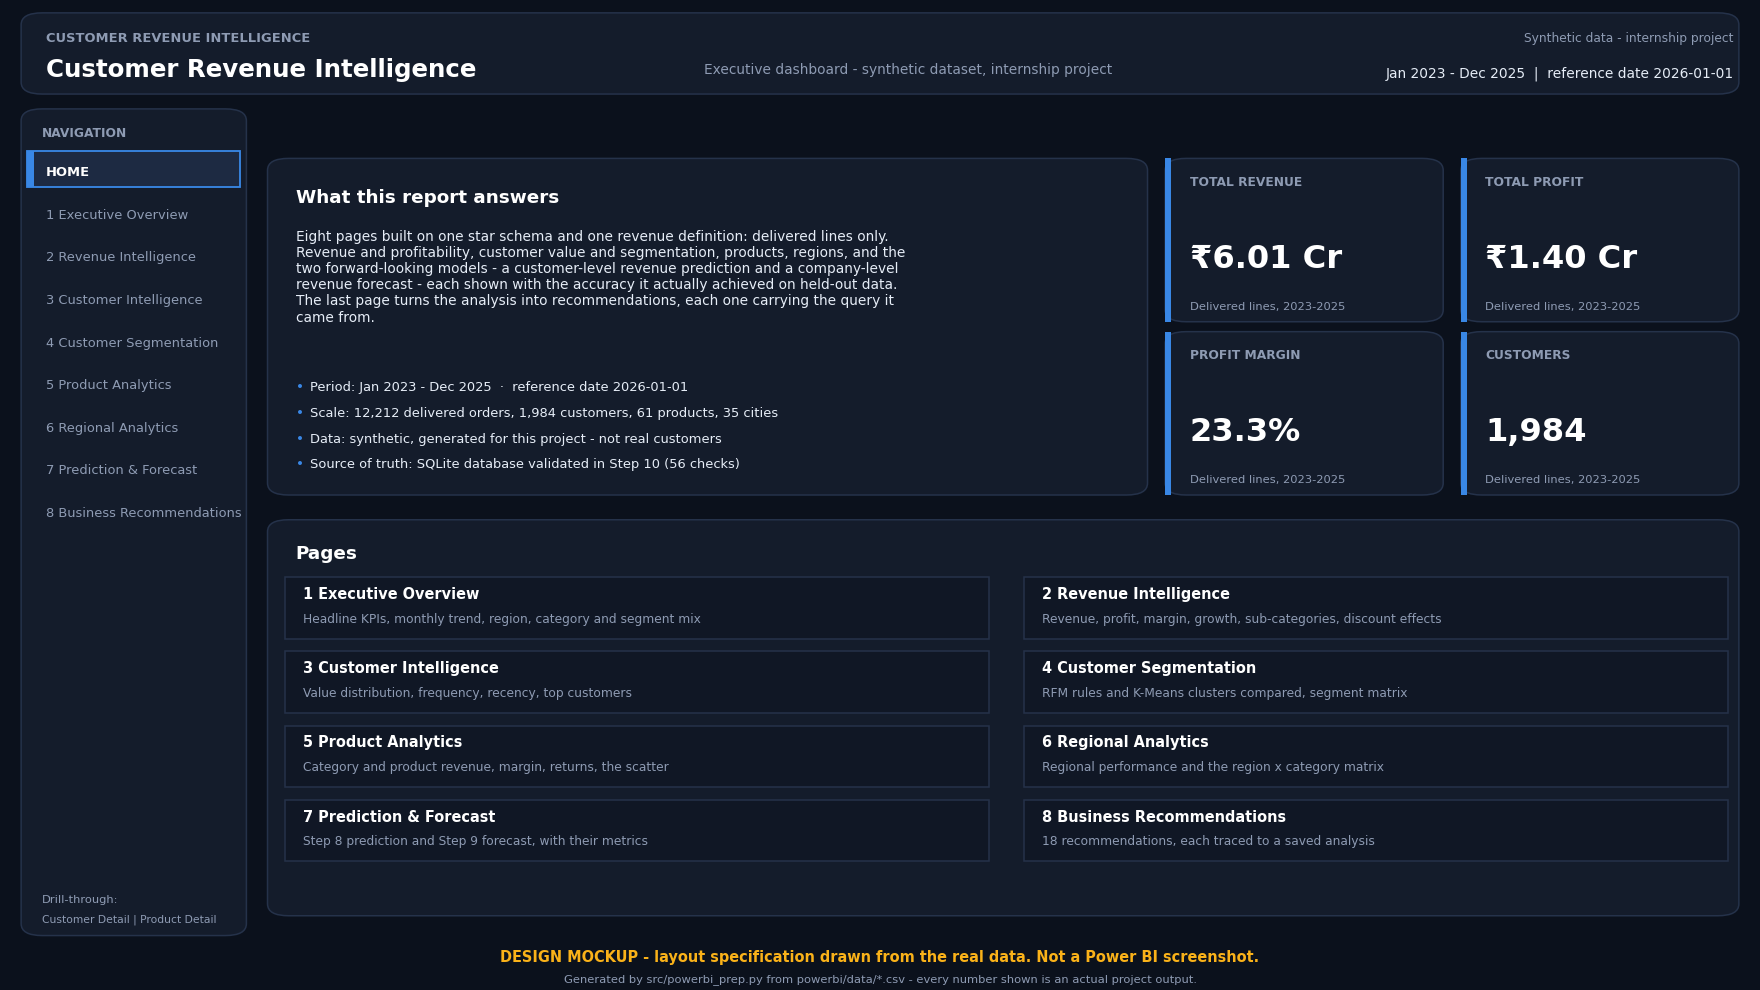

In [13]:
Image(str(MOCK / "00_home_mockup.png"))

### 1 Executive Overview

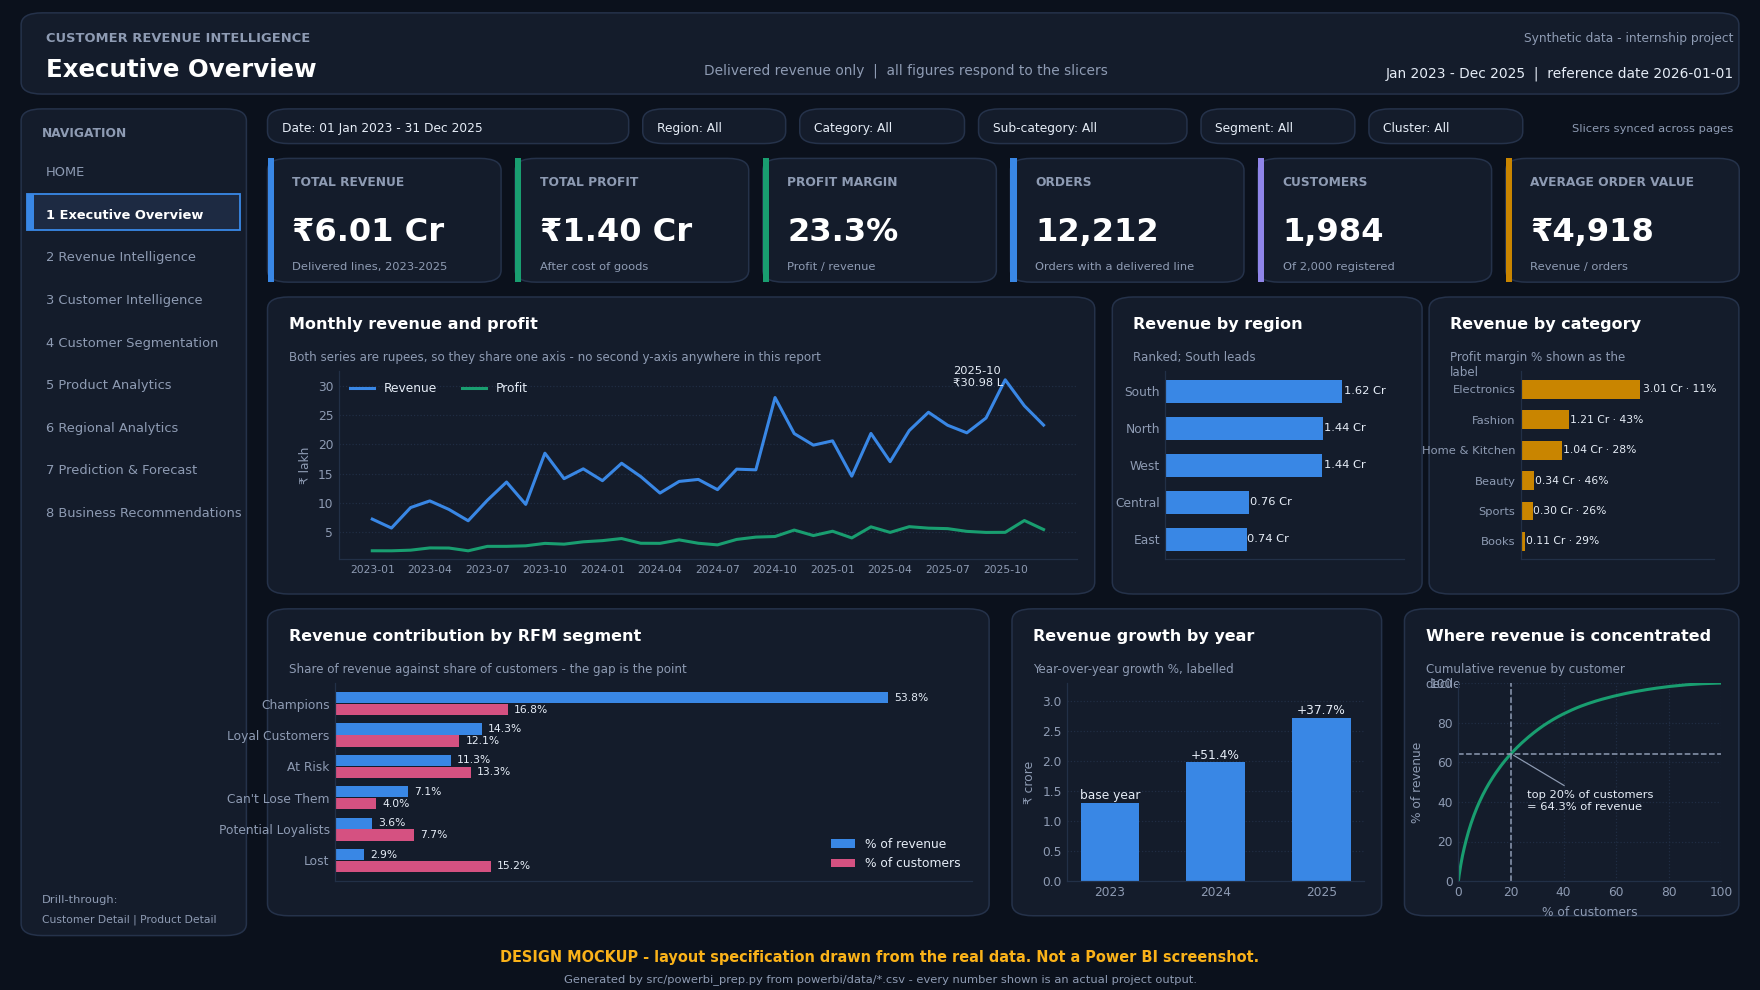

In [14]:
Image(str(MOCK / "01_executive_overview_mockup.png"))

### 2 Revenue Intelligence

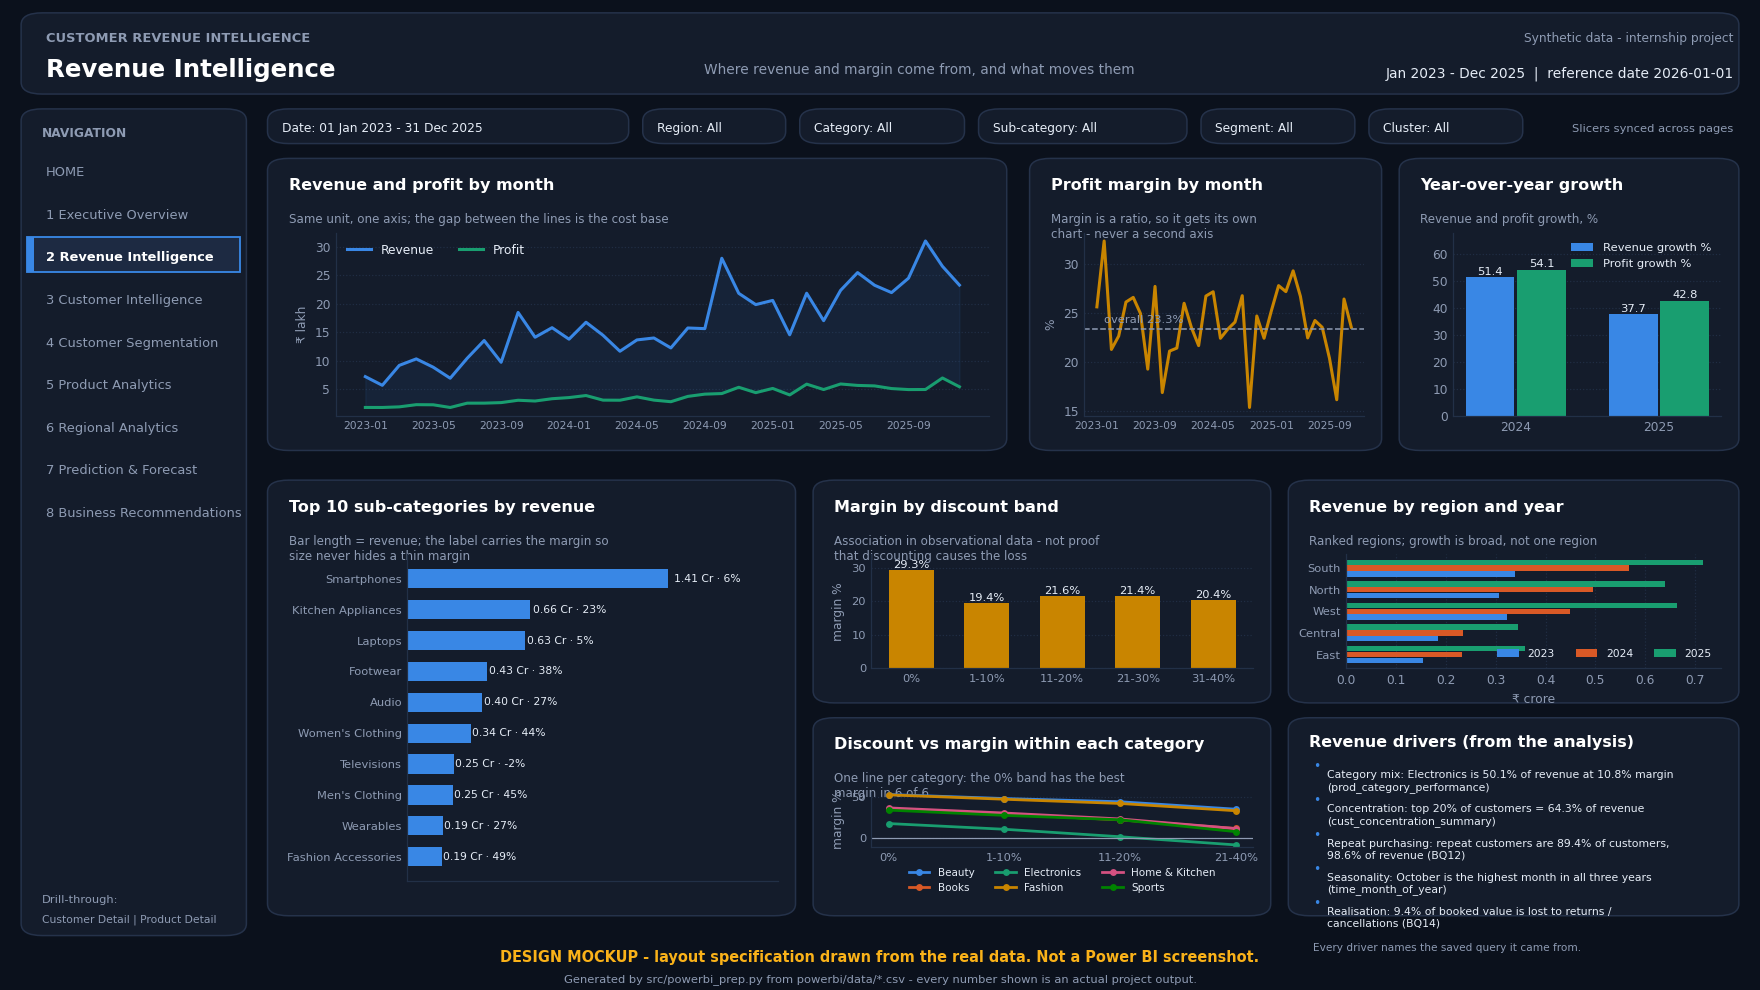

In [15]:
Image(str(MOCK / "02_revenue_intelligence_mockup.png"))

### 3 Customer Intelligence

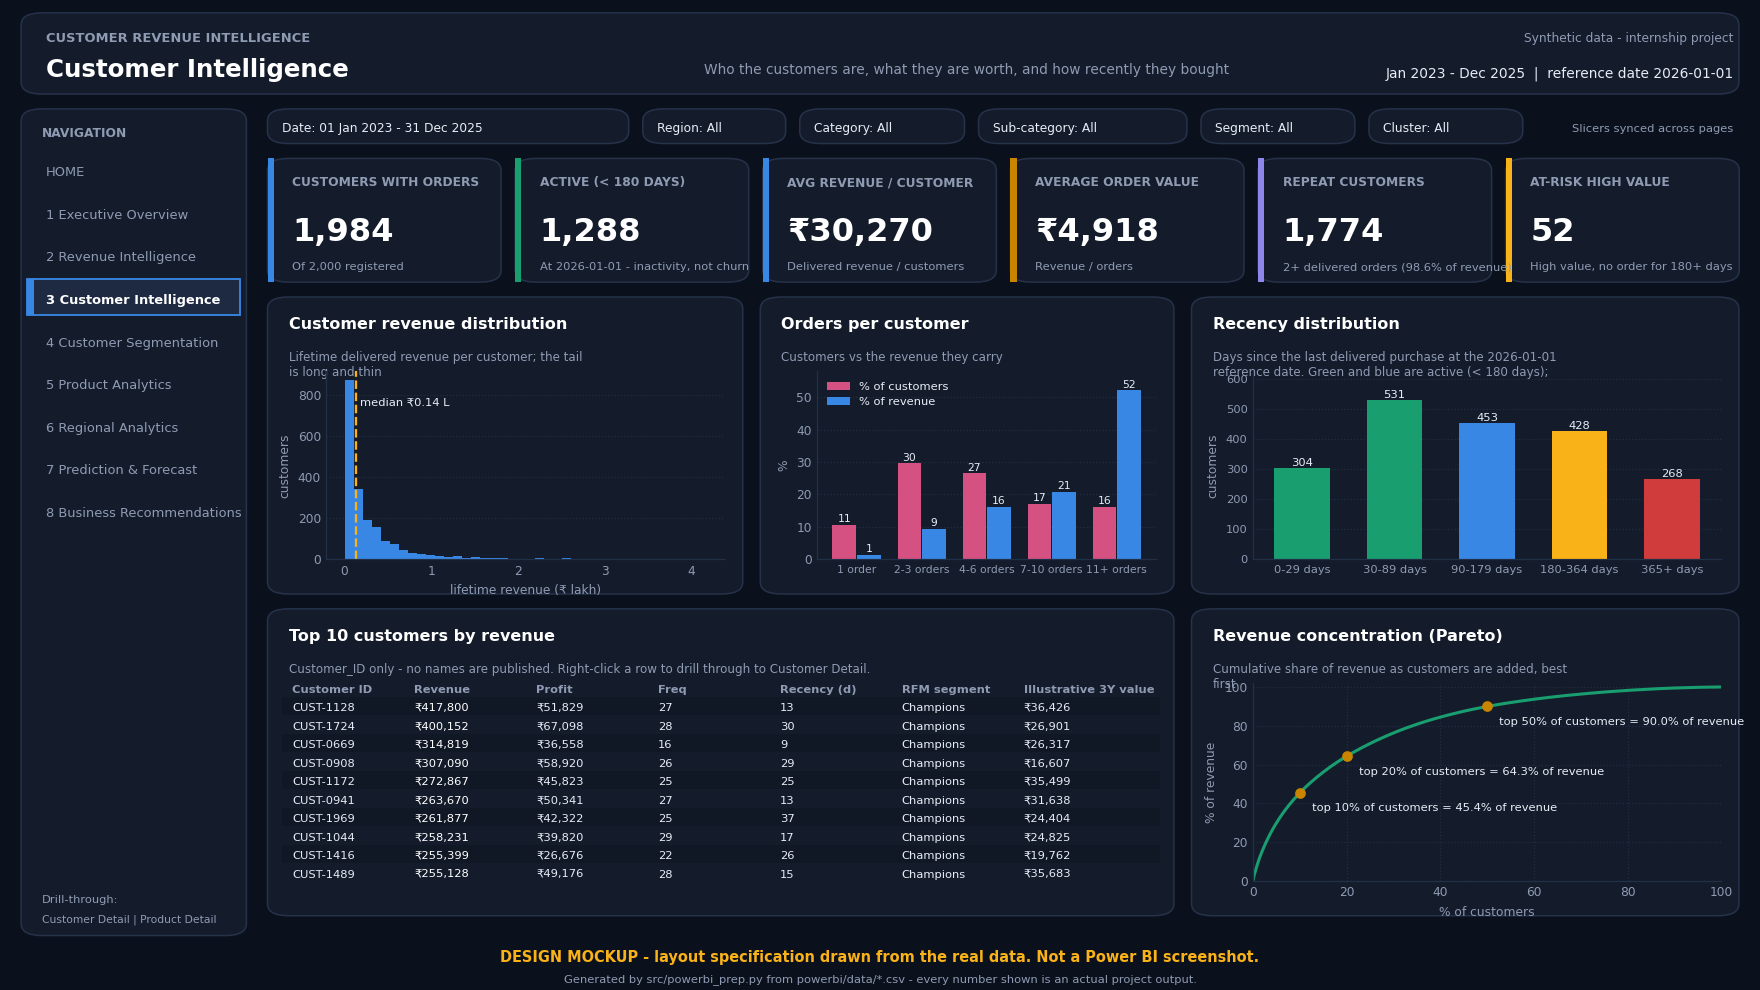

In [16]:
Image(str(MOCK / "03_customer_intelligence_mockup.png"))

### 4 Customer Segmentation

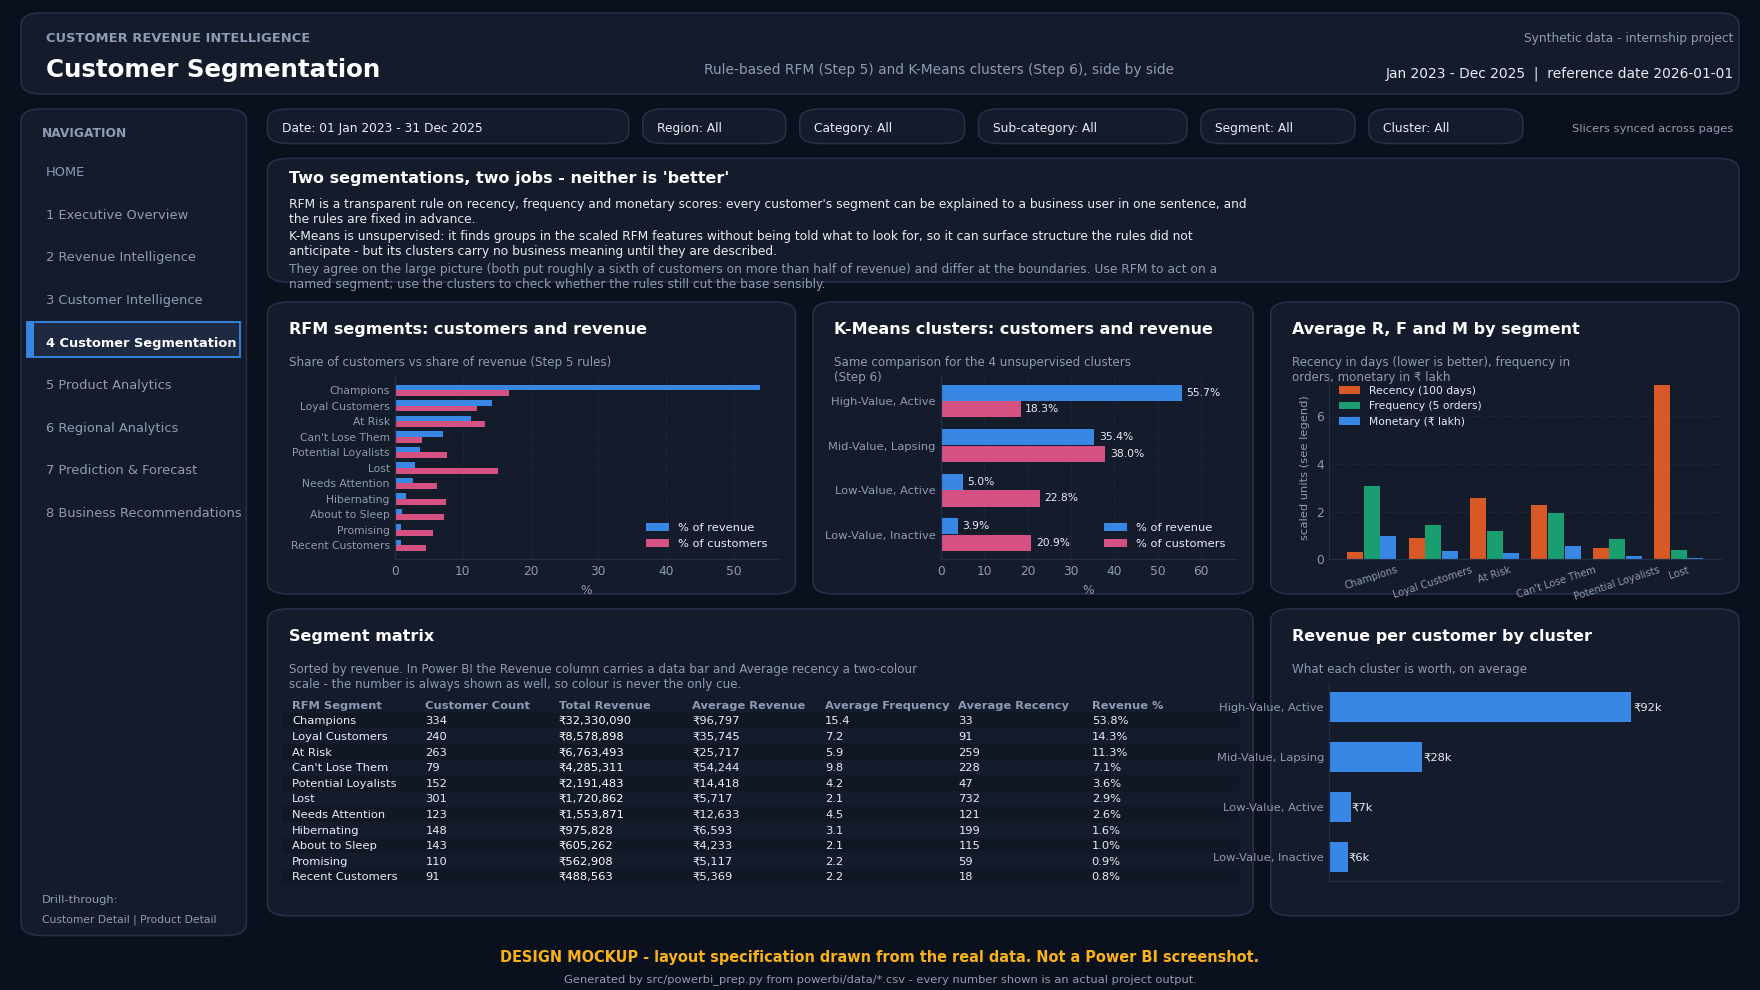

In [17]:
Image(str(MOCK / "04_customer_segmentation_mockup.png"))

### 5 Product Analytics

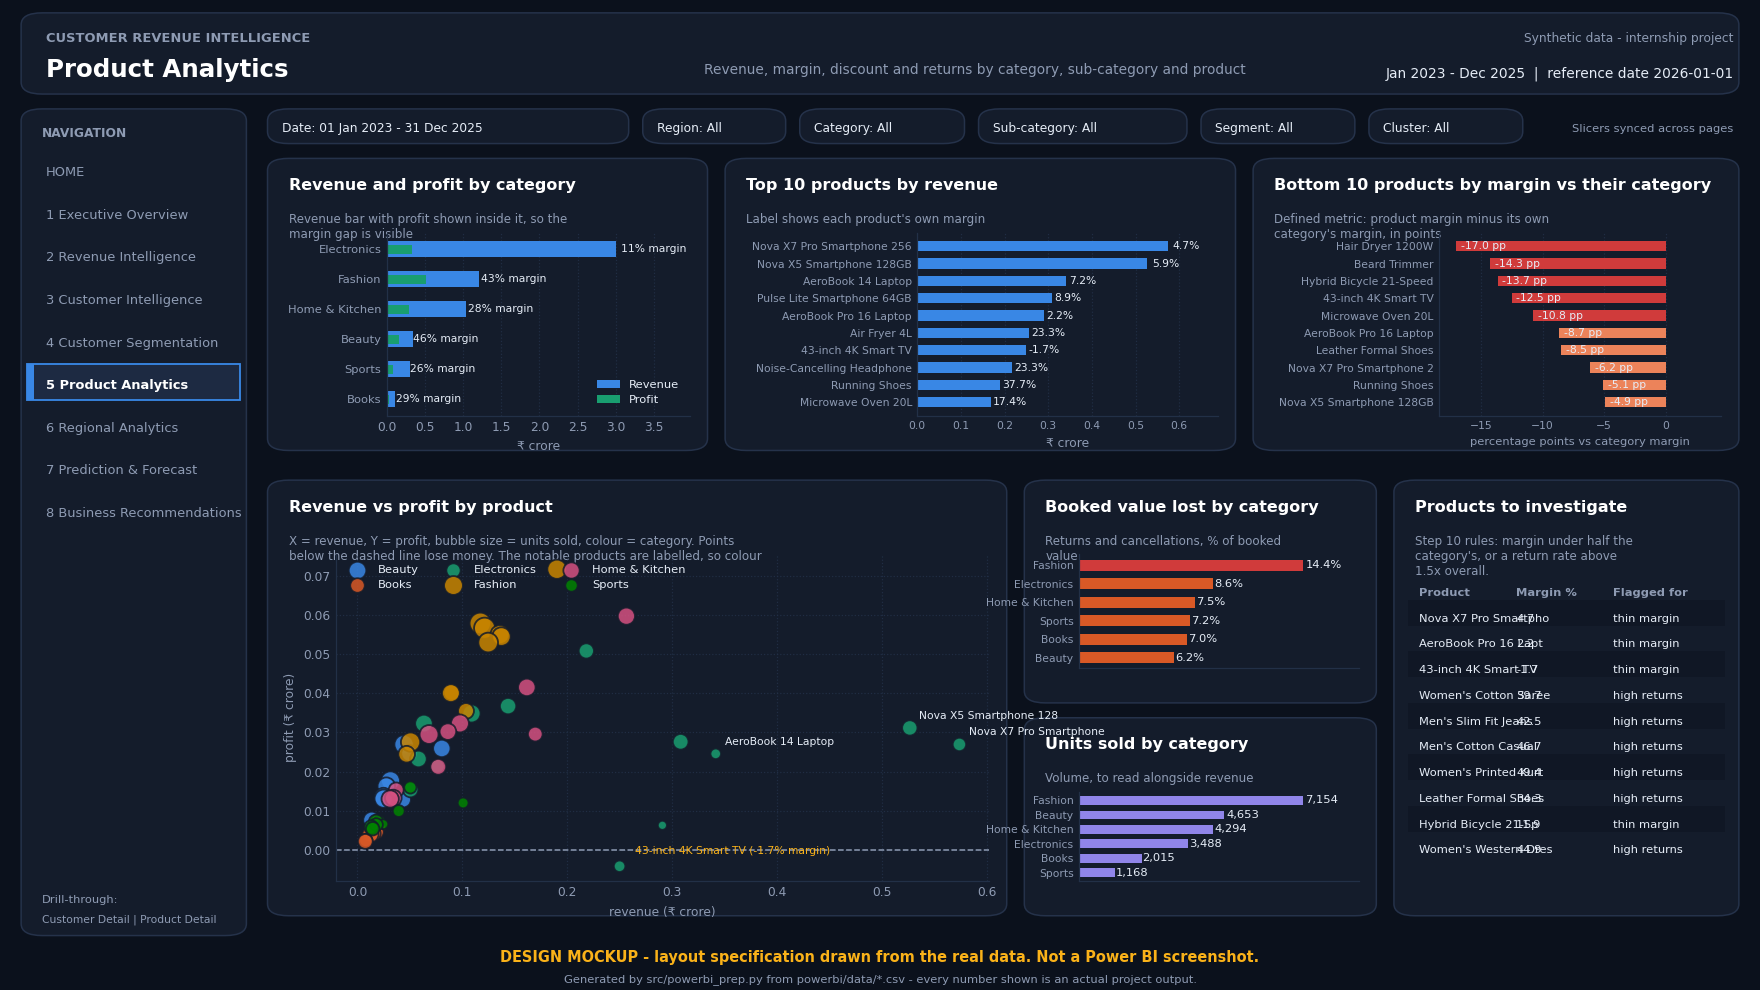

In [18]:
Image(str(MOCK / "05_product_analytics_mockup.png"))

### 6 Regional Analytics

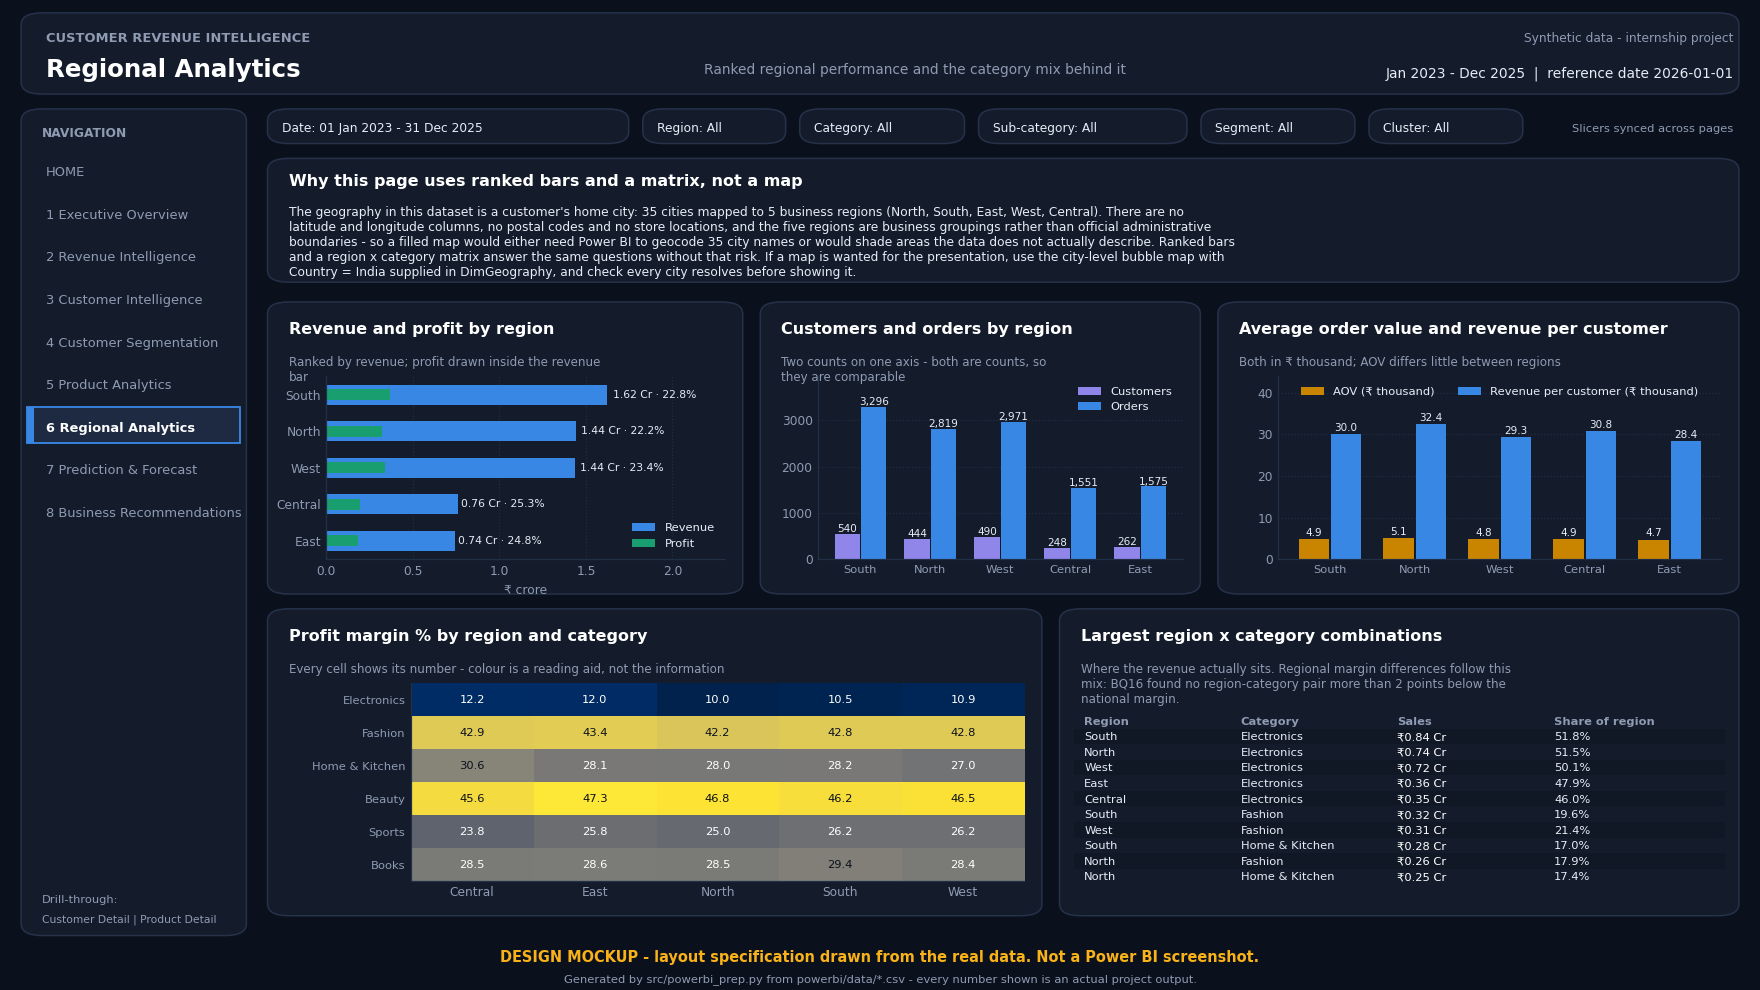

In [19]:
Image(str(MOCK / "06_regional_analytics_mockup.png"))

### 7 Prediction & Forecast

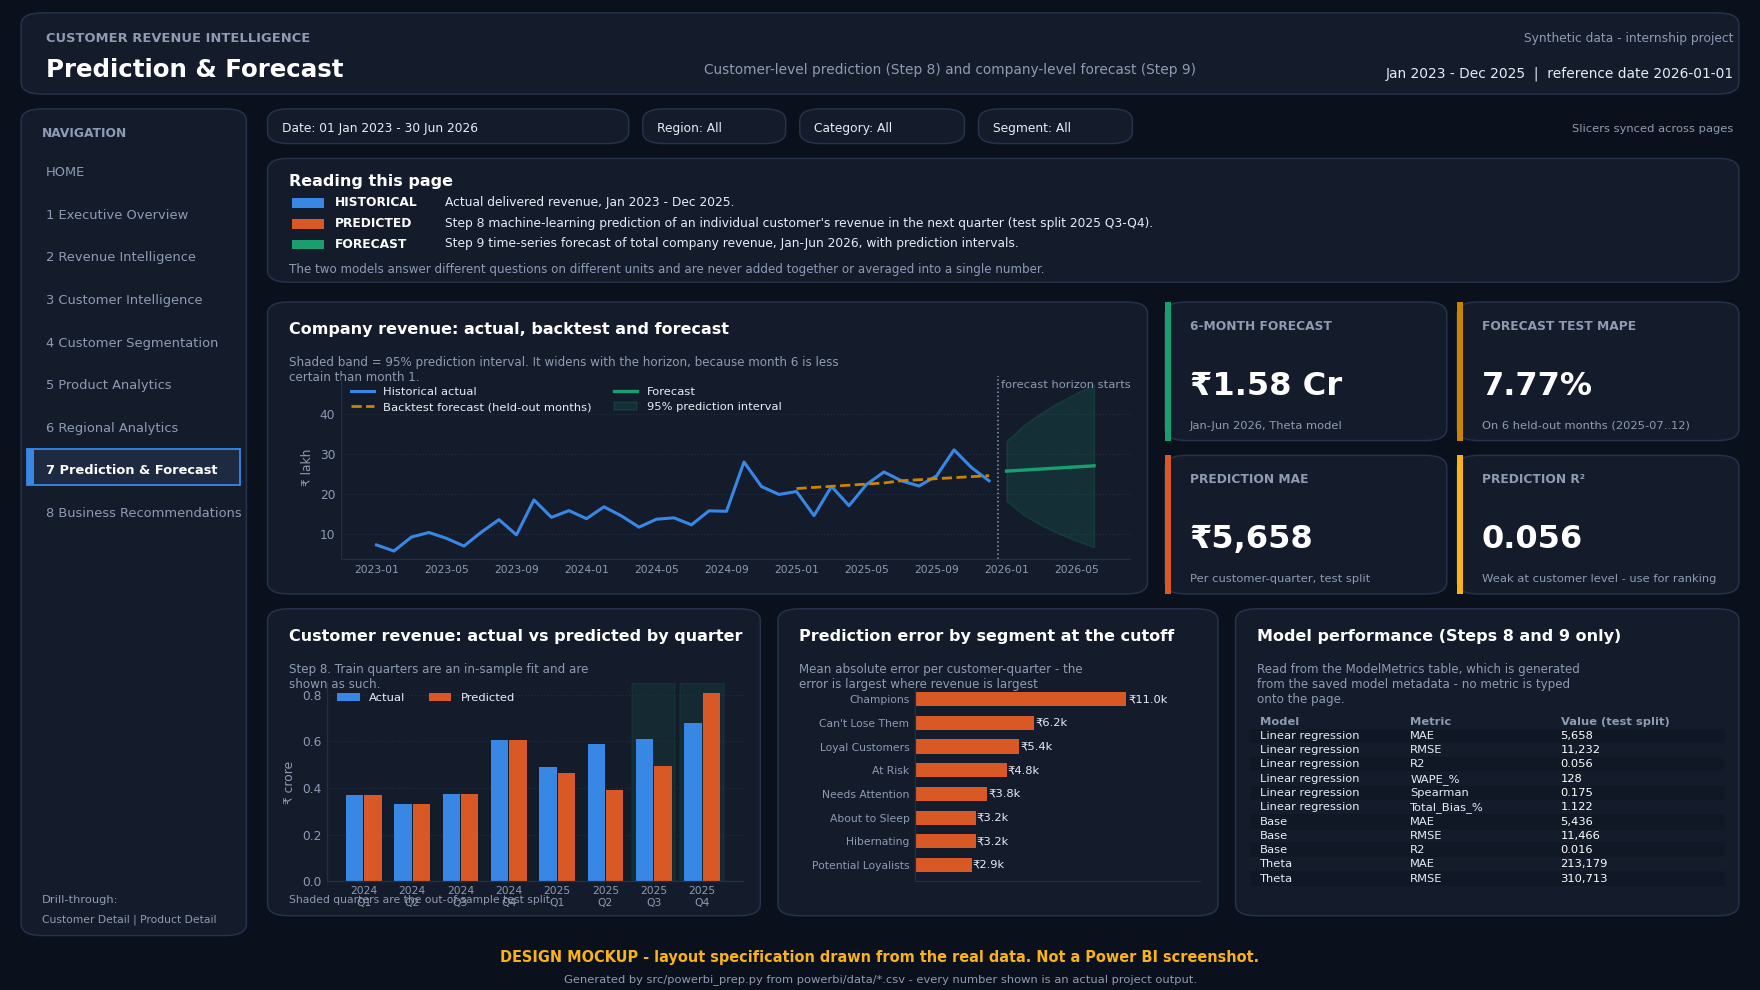

In [20]:
Image(str(MOCK / "07_prediction_forecast_mockup.png"))

### 8 Business Recommendations

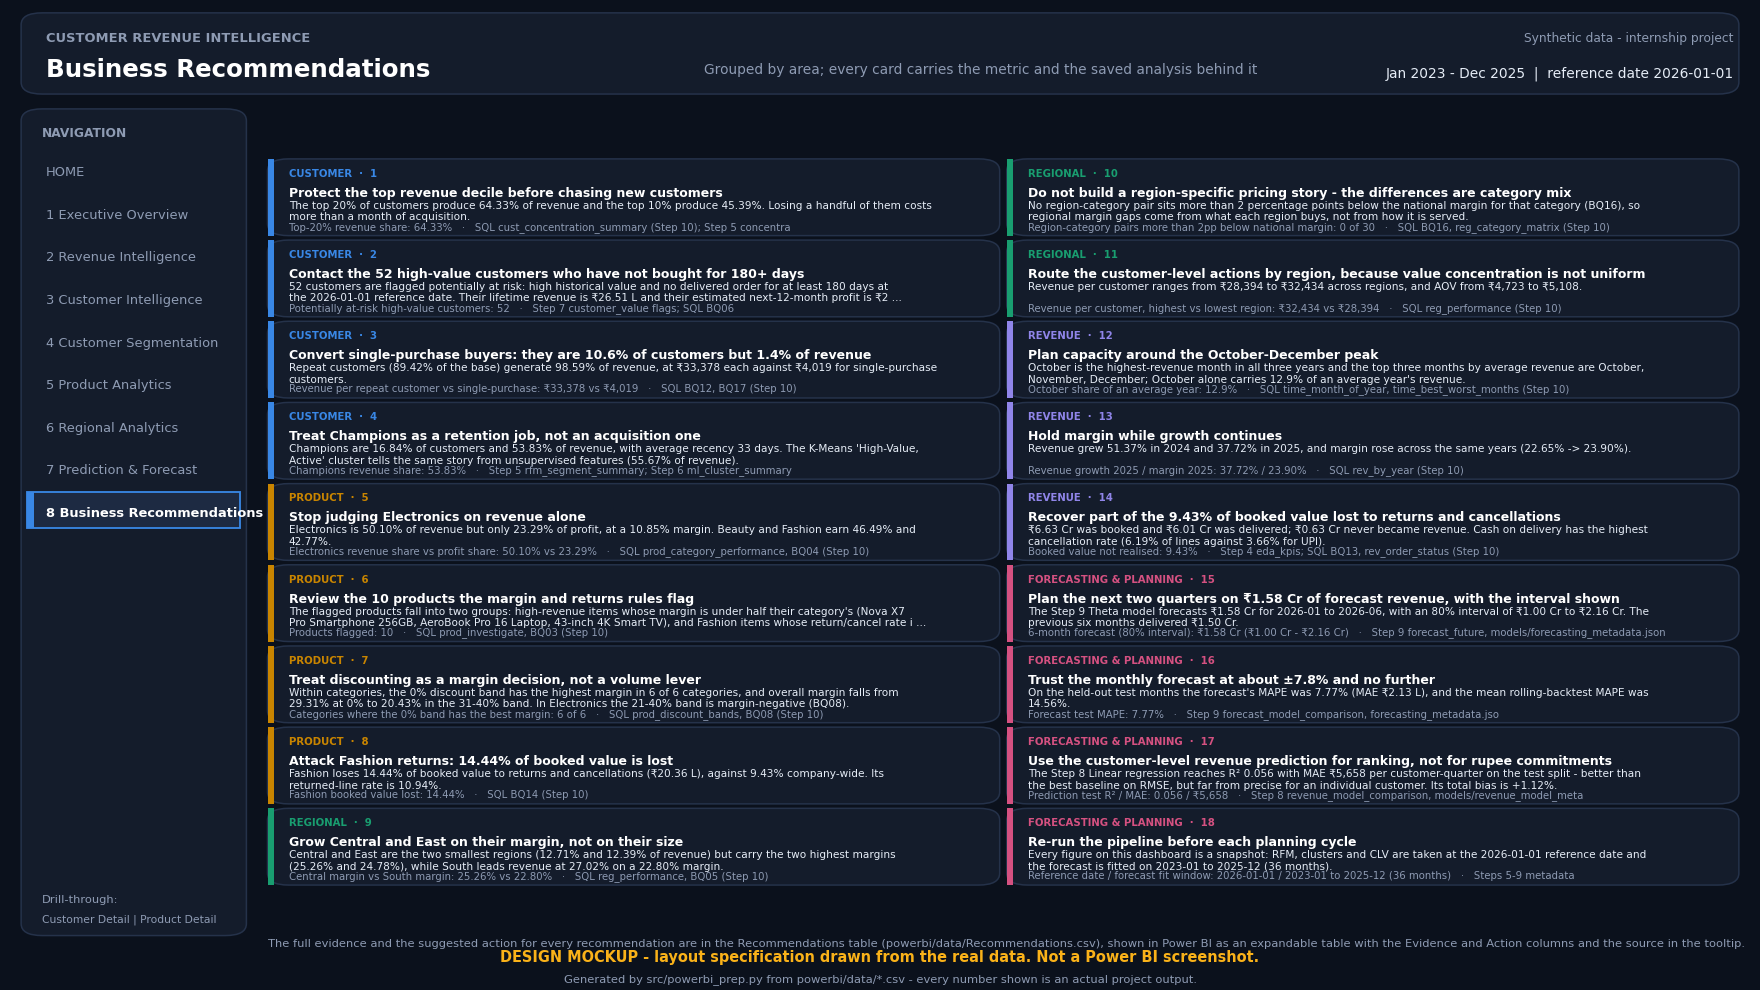

In [21]:
Image(str(MOCK / "08_business_recommendations_mockup.png"))

### Customer Detail (drill-through)

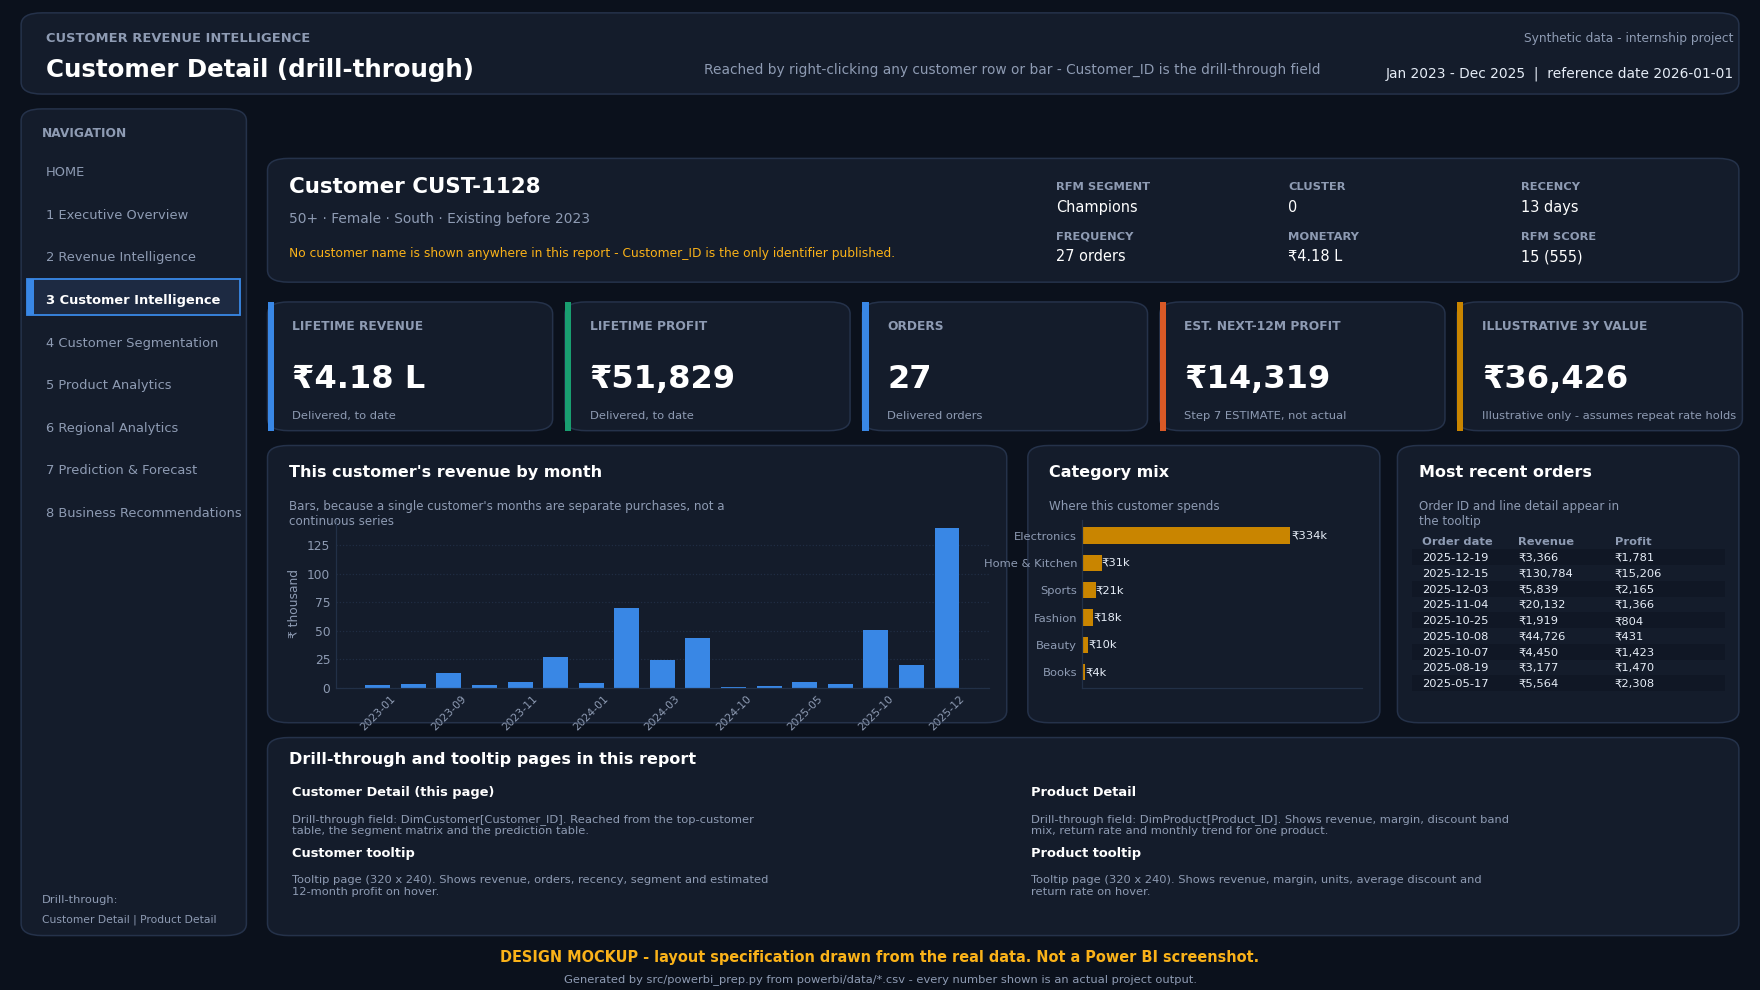

In [22]:
Image(str(MOCK / "09_customer_detail_drillthrough_mockup.png"))

## 10. What still has to be done by hand, and what is already done

In [23]:
R["checklist"]

,Checklist_Item,Status,Evidence
0,Power BI data model created,Done (files),13 tables exported to powerbi/data/ from the pbi_* SQL views; catalogue in powerbi/tab...
1,Relationships validated,Done (files) + Validated (Python),"9 relationships specified in powerbi/relationships.csv with cardinality, cross-filter ..."
2,Date table created,Done (files),"DimDate: 1,277 daily rows, 2023-01-01 to 2026-06-30, with Year, Quarter, Month Number,..."
3,DAX measures created,Done (files),"84 measures in powerbi/dax/measures.dax, grouped into 10 display folders, each with it..."
4,Core KPI values reconciled with SQL/Python,Validated (Python/SQL),15 measures x 8 filter contexts recomputed in pandas; the four required measures plus ...
5,Executive Overview created,Specified + mockup,"Layout, visuals and measures specified; design mockup 01. Building the page in Power B..."
6,Revenue Intelligence created,Specified + mockup,"Layout, visuals and measures specified; design mockup 02. Building the page is manual."
7,Customer Intelligence created,Specified + mockup,"Layout, visuals and measures specified; design mockup 03. Building the page is manual."
8,Customer Segmentation created,Specified + mockup,"Layout, visuals and measures specified; design mockup 04. Building the page is manual."
9,Product Analytics created,Specified + mockup,"Layout, visuals and measures specified; design mockup 05. Building the page is manual."


- Statuses are honest: **"Done (files)"** and **"Validated (Python/SQL)"** for what ran here,
  **"Specified + mockup"** for pages that exist as a specification, and nothing claims a Power BI
  screenshot was taken.
- The manual steps are in `powerbi/POWERBI_BUILD_GUIDE.md`; the reading guide for business users is
  `outputs/reports/powerbi_user_guide.md`.